# CardioRitmo · Tamizaje de latidos anormales (DEV)

**Cliente:** CardioRitmo, fabricante de monitores Holter.
**Objetivo:** que el monitor marque los latidos anormales para que el cardiólogo revise solo esos.

**Especificaciones del cliente (en la prueba, umbral 0.5):**
- sensibilidad ≥ 95 % (de cada 100 latidos anormales, marcar al menos 95);
- especificidad ≥ 95 % (de cada 100 latidos normales, no marcar más de 5);
- el modelo cabe en el monitor: **≤ 20,000 parámetros**.

Todas las decisiones se toman con la **validación**; la prueba del cliente se usa **una sola vez, al final**.

In [ ]:
import os

# TF en Windows no ve la GPU; Keras 3 sobre PyTorch sí
os.environ["KERAS_BACKEND"] = "torch"

import keras
import matplotlib.pyplot as plt
import numpy as np
import torch

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
print(
    "Keras",
    keras.__version__,
    "| backend:",
    keras.backend.backend(),
    "| GPU:",
    torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no",
)

Keras 3.15.1 | backend: torch | GPU: NVIDIA GeForce GTX 1660 SUPER


## 1. Datos
ECG5000 (archivo UCR): latidos de 140 puntos de **un solo paciente** con insuficiencia cardiaca (BIDMC, PhysioNet).
Carga y división **exactamente** como las pide el cliente.

In [ ]:
# fmt: off
import pandas as pd
from sklearn.model_selection import train_test_split

ecg = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv", header=None)
X = ecg.iloc[:, :-1].to_numpy("float32")   # 140 puntos por latido
y = 1 - ecg.iloc[:, -1].to_numpy("int64")  # el archivo trae 1 = normal; aquí 1 = ANORMAL

# Prueba del cliente: 20 % estratificado. No la toquen hasta el final.
X_resto, X_prueba, y_resto, y_prueba = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# Con X_resto y y_resto armen su entrenamiento y su validación como quieran.

## 2. Exploración
Tamaño y balance de clases. A partir de aquí la exploración usa **solo `X_resto`**, para no mirar la prueba.

In [ ]:
print("Latidos totales:", X.shape[0], "| puntos por latido:", X.shape[1])
print("Valores faltantes:", int(np.isnan(X).sum()))
balance = pd.DataFrame(
    {
        "total": pd.Series(y).value_counts(),
        "resto": pd.Series(y_resto).value_counts(),
        "prueba": pd.Series(y_prueba).value_counts(),
    }
).rename(index={0: "normal (0)", 1: "anormal (1)"})
balance.loc["% anormal"] = (balance.loc["anormal (1)"] / balance.sum() * 100).round(1)
balance

Latidos totales: 4998 | puntos por latido: 140
Valores faltantes: 0


,total,resto,prueba
normal (0),2919.0,2335.0,584.0
anormal (1),2079.0,1663.0,416.0
% anormal,41.6,41.6,41.6


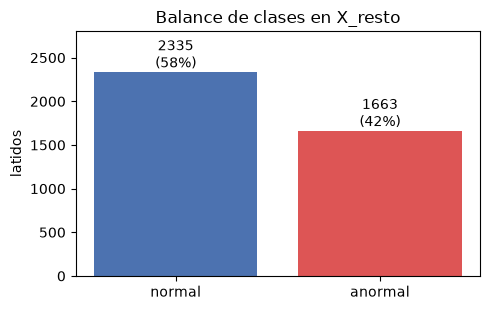

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3.2))
conteo = pd.Series(y_resto).value_counts().sort_index()
ax.bar(["normal", "anormal"], conteo.values, color=["#4C72B0", "#DD5555"])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v}\n({v / conteo.sum():.0%})", ha="center", va="bottom")
ax.set_title("Balance de clases en X_resto")
ax.set_ylabel("latidos")
ax.set_ylim(0, conteo.max() * 1.2)
plt.tight_layout()
plt.show()

**Ejemplos:** cinco latidos de cada clase, elegidos al azar.

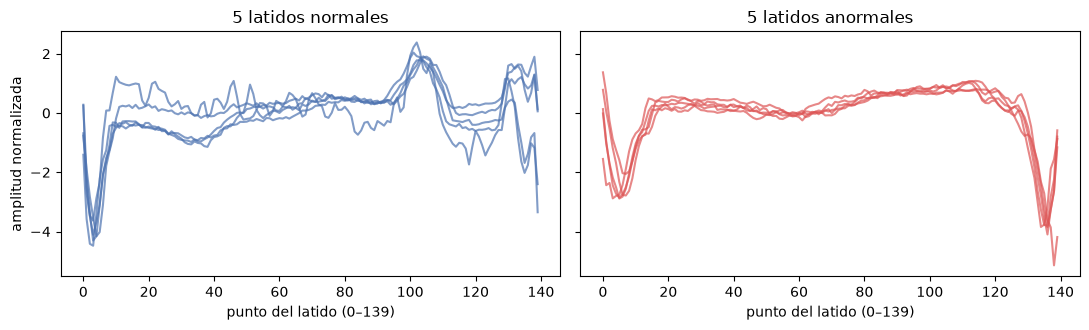

In [ ]:
rng = np.random.default_rng(SEMILLA)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, clase, nombre, color in zip(
    axes, [0, 1], ["normales", "anormales"], ["#4C72B0", "#DD5555"]
):
    for i in rng.choice(np.where(y_resto == clase)[0], 5, replace=False):
        ax.plot(X_resto[i], color=color, alpha=0.7)
    ax.set_title(f"5 latidos {nombre}")
    ax.set_xlabel("punto del latido (0–139)")
axes[0].set_ylabel("amplitud normalizada")
plt.tight_layout()
plt.show()

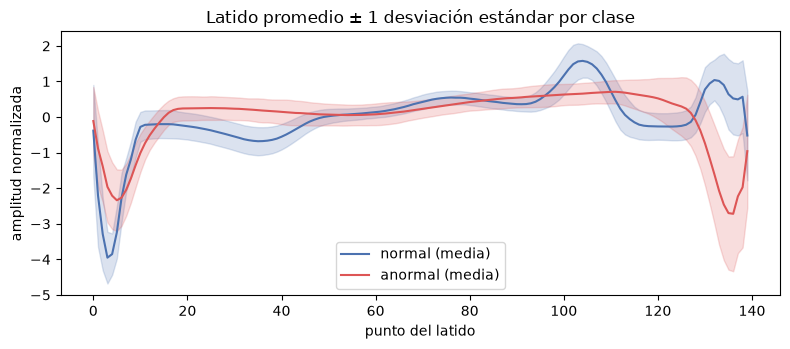

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for clase, nombre, color in [(0, "normal", "#4C72B0"), (1, "anormal", "#DD5555")]:
    m, s = X_resto[y_resto == clase].mean(0), X_resto[y_resto == clase].std(0)
    ax.plot(m, color=color, label=f"{nombre} (media)")
    ax.fill_between(range(140), m - s, m + s, color=color, alpha=0.2)
ax.set_title("Latido promedio ± 1 desviación estándar por clase")
ax.set_xlabel("punto del latido")
ax.set_ylabel("amplitud normalizada")
ax.legend()
plt.tight_layout()
plt.show()

**Lo que vemos:**
- 4,998 latidos de 140 puntos, sin valores faltantes; ~42 % son anormales, así que las clases están razonablemente balanceadas.
- Las dos clases se separan con claridad en la forma promedio (sobre todo al final del latido), lo que sugiere que un modelo pequeño puede bastar.
- El latido anormal típico pierde el pico cercano al punto 105 y cae al final (puntos 125–139); su banda de ±1 desviación es más ancha ahí, así que los anormales con forma atípica serán los errores difíciles.
- **Límite importante:** todo viene de un solo paciente; lo que aprendamos describe *sus* latidos, no los de cualquier persona.